In [1]:
from pathlib import Path
import yaml
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

print("Libraries imported successfully!")

Libraries imported successfully!


Path: للتعامل مع مسارات الملفات والمجلدات.
yaml: لقراءة إعدادات الداتا من ملف data.yaml.
pandas: لتنظيم البيانات وتحليلها.
matplotlib: لعرض الرسومات وتحليل النتائج.
PIL: لفتح الصور والتعامل معاها.
Counter: لعدّ وتلخيص تكرار الفئات.

In [2]:
PROJECT_DIR = Path(r"C:\Users\pc\Downloads\depi")
DATA_DIR = PROJECT_DIR / "data"
DATA_YAML = DATA_DIR / "data.yaml"

print("Project directory exists:", PROJECT_DIR.exists())
print("Dataset directory exists:", DATA_DIR.exists())
print("YAML file exists:", DATA_YAML.exists())

Project directory exists: True
Dataset directory exists: True
YAML file exists: True


هنحدد مكان المشروع ومجلد الداتا وملف الإعدادات، علشان نقدر نوصل للصور والملفات بسهولة في باقي الكود. وبعدها هنتأكد إن المسارات دي موجودة فعلًا على الجهاز

هنقرأ ملف "data.yaml" علشان نعرف عدد الفئات اللي الموديل هيتعامل معاها، وأسماء كل فئة ورقمهاالتدريب.

In [3]:
with open(DATA_YAML, "r", encoding="utf-8") as file:
    data_config = yaml.safe_load(file)

print("Number of classes:", data_config["nc"])
print("\nClass names:")

for class_id, class_name in enumerate(data_config["names"]):
    print(f"{class_id}: {class_name}")

Number of classes: 6

Class names:
0: freshapples
1: freshbanana
2: freshoranges
3: rottenapples
4: rottenbanana
5: rottenoranges


هنا هنحسب عدد الصور وملفات الـ Labels الموجودة في كل جزء من الداتا، سواء التدريب أو التحقق أو الاختبار. الهدف إننا نتأكد إن التقسيمات موجودة ونعرف حجم كل جزء قبل ما نبدأ تدريب الموديل.

In [4]:
splits = {
    "train": DATA_DIR / "train",
    "valid": DATA_DIR / "valid",
    "test": DATA_DIR / "test",
}

for split_name, split_dir in splits.items():
    images_dir = split_dir / "images"
    labels_dir = split_dir / "labels"

    image_count = sum(1 for _ in images_dir.iterdir() if _.is_file()) if images_dir.exists() else 0
    label_count = len(list(labels_dir.glob("*.txt"))) if labels_dir.exists() else 0

    print(f"{split_name}: Images = {image_count:,} | Labels = {label_count:,}")

train: Images = 66,577 | Labels = 66,577
valid: Images = 2,038 | Labels = 2,038
test: Images = 2,038 | Labels = 2,038


هنراجع ملفات الـ Labels علشان نتأكد إن بيانات تحديد أماكن الفاكهة مكتوبة بالشكل الصحيح، وإن أرقام الفئات والإحداثيات صالحة. الفحص ده هيساعدنا نكتشف أي مشاكل ممكن تأثر على تدريب الموديل.


In [5]:
for split_name, split_dir in splits.items():
    labels_dir = split_dir / "labels"

    total_files = 0
    empty_files = 0
    invalid_lines = 0
    total_lines = 0

    for label_file in labels_dir.glob("*.txt"):
        total_files += 1
        lines = label_file.read_text(encoding="utf-8").splitlines()

        if not any(line.strip() for line in lines):
            empty_files += 1

        for line in lines:
            if not line.strip():
                continue

            total_lines += 1
            parts = line.split()

            try:
                values = [float(value) for value in parts]
                class_id = int(values[0])

                valid = (
                    len(values) == 5
                    and values[0] == class_id
                    and 0 <= class_id < data_config["nc"]
                    and all(0 <= value <= 1 for value in values[1:])
                    and values[3] > 0
                    and values[4] > 0
                )
            except (ValueError, IndexError):
                valid = False

            if not valid:
                invalid_lines += 1

    print(f"\n{split_name}")
    print(f"Label files: {total_files:,}")
    print(f"Empty files: {empty_files:,}")
    print(f"Total annotation lines: {total_lines:,}")
    print(f"Invalid lines: {invalid_lines:,}")


train
Label files: 66,577
Empty files: 0
Total annotation lines: 74,198
Invalid lines: 9,030

valid
Label files: 2,038
Empty files: 0
Total annotation lines: 2,261
Invalid lines: 299

test
Label files: 2,038
Empty files: 0
Total annotation lines: 2,260
Invalid lines: 283


In [6]:
label_file = next((DATA_DIR / "train" / "labels").glob("*.txt"))

print("File:", label_file.name)
print(label_file.read_text(encoding="utf-8")[:1000])

File: rotated_by_15_Screen-Shot-2018-06-07-at-2_15_20-PM_png.rf.000893140a4c61f307841c2f438f78a5.txt
3 0.5273901013297755 0.48046875 0.9125290356633563 0.959375


In [8]:
found_issue = False

for label_file in (DATA_DIR / "train" / "labels").glob("*.txt"):
    for line in label_file.read_text(encoding="utf-8").splitlines():
        parts = line.split()

        if len(parts) != 5:
            print("File:", label_file.name)
            print("Label:", line[:300])
            found_issue = True
            break

    if found_issue:
        break

if not found_issue:
    print("All training labels contain exactly 5 values.")

File: rotated_by_15_Screen-Shot-2018-06-07-at-2_22_39-PM_png.rf.099d7f74734eb88a777258d69b1acd9e.txt
Label: 3 0.2694063921875 0.9034653468749999 0.3287671234375 0.9331683171874999 0.39269406406249996 0.94306930625 0.45433789999999996 0.9356435640624999 0.6027397265625 0.9034653468749999 0.6598173515625 0.8737623765625001 0.726027396875 0.809405940625 0.7785388125 0.7326732671875 0.8105022828124999 0.67574


In [ ]:
for split_name, split_dir in splits.items():
    invalid = 0

    for label_file in (split_dir / "labels").glob("*.txt"):
        for line in label_file.read_text(encoding="utf-8").splitlines():
            parts = line.split()

            try:
                values = [float(x) for x in parts]
                class_id = int(values[0])

                valid = (
                    len(values) >= 5
                    and len(values[1:]) % 2 == 0
                    and values[0] == class_id
                    and 0 <= class_id < data_config["nc"]
                    and all(0 <= x <= 1 for x in values[1:])
                )
            except (ValueError, IndexError):
                valid = False

            if not valid:
                invalid += 1

    print(f"{split_name}: Invalid annotations = {invalid:,}")

train: Invalid annotations = 0
valid: Invalid annotations = 0
test: Invalid annotations = 0


هنعرض صورة من مجموعة التدريب علشان نشوف شكل الداتا فعليًا، ونتأكد إن الصور مناسبة للمهمة قبل ما نبدأ تدريب الموديل.

Image: rotated_by_15_Screen-Shot-2018-06-07-at-2_15_20-PM_png.rf.000893140a4c61f307841c2f438f78a5.jpg
Image size: (640, 640)


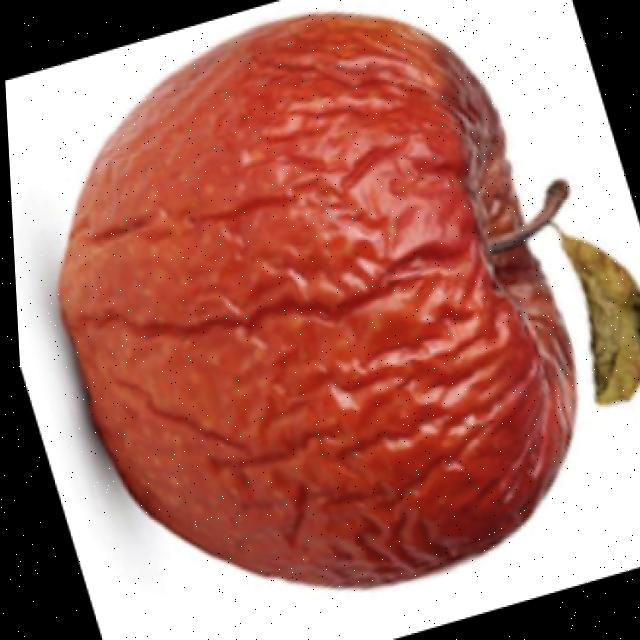

In [ ]:
image_file = next((DATA_DIR / "train" / "images").iterdir())

image = Image.open(image_file)

print("Image:", image_file.name)
print("Image size:", image.size)
display(image)

هنعرض أماكن الفاكهة المحددة في ملفات الـ Labels فوق الصور، علشان نتأكد إن البيانات بتحدد مكان الفاكهة بشكل صحيح قبل تدريب الموديل.

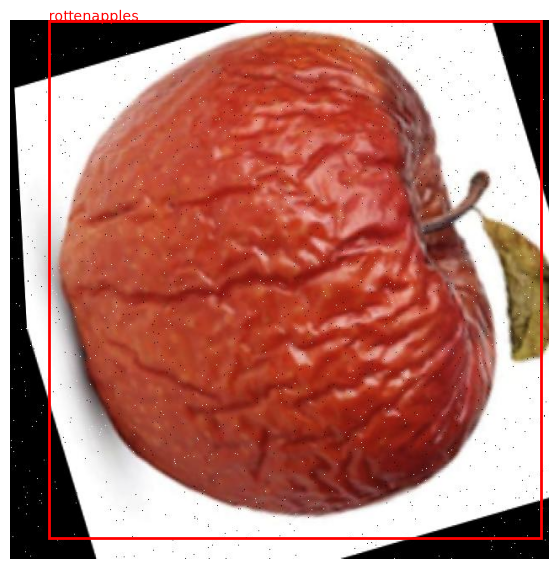

In [ ]:
image_file = next((DATA_DIR / "train" / "images").iterdir())
label_file = DATA_DIR / "train" / "labels" / (image_file.stem + ".txt")

image = Image.open(image_file).convert("RGB")
plt.figure(figsize=(7, 7))
plt.imshow(image)

with open(label_file, "r", encoding="utf-8") as file:
    for line in file:
        values = line.split()
        if len(values) == 5:
            class_id, x, y, w, h = map(float, values)
            x1 = (x - w / 2) * image.width
            y1 = (y - h / 2) * image.height
            rect = plt.Rectangle((x1, y1), w * image.width, h * image.height,
                                 fill=False, edgecolor="red", linewidth=2)
            plt.gca().add_patch(rect)
            plt.text(x1, y1, data_config["names"][int(class_id)], color="red")

plt.axis("off")
plt.show()

اخترنا YOLO11n كبداية لأنه موديل صغير بيستخدم في اكتشاف الأجسام داخل الصور. هنستخدمه للتعرف على أنواع الفاكهة الموجودة في الداتا وحالتها

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("Model loaded successfully!")

Model loaded successfully!


تجهيز مسارات الداتا للتدريب

ملف "data.yaml" فيه أسماء الفئات ومسارات الصور. هنا هنتأكد إن مسارات التدريب والتحقق والاختبار بتوصل للمجلدات الصحيحة، علشان الموديل يقدر يقرأ الصور وقت التدريب والتقييم.

هننشئ نسخة إعدادات داخل المشروع بدل ما نغيّر الملف الأصلي بتاع الداتا.

In [ ]:
train_config = {
    "path": str(DATA_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": data_config["nc"],
    "names": data_config["names"],
}

TRAIN_YAML = PROJECT_DIR / "cv_data.yaml"

with open(TRAIN_YAML, "w", encoding="utf-8") as file:
    yaml.safe_dump(train_config, file, sort_keys=False)

print("Training config saved:", TRAIN_YAML)

Training config saved: D:\projects_Depi\cv_data.yaml


قبل ما نبدأ التدريب، هنتأكد إن مجلدات الصور الخاصة بالتدريب والتحقق والاختبار موجودة في المسارات اللي حددناها، علشان نتجنب أي مشكلة في قراءة الداتا.

In [ ]:
for split in ["train", "valid", "test"]:
    path = DATA_DIR / split / "images"
    print(f"{split}: {path.exists()}")

train: True
valid: True
test: True


بعد ما جهزنا الداتا واخترنا الموديل، هنبدأ تدريبه على صور التدريب، مع استخدام مجموعة التحقق لمتابعة الأداء أثناء التدريب. هنبدأ بـ 10 epochs كتجربة أولية، وبعد ما نشوف النتائج نقرر إذا كنا محتاجين نزود مدة التدريب.

In [ ]:
results = model.train(
    data=str(TRAIN_YAML),
    epochs=10,
    imgsz=640,
    batch=16,
    device=0
)

Ultralytics 8.4.183  Python-3.13.15 torch-2.13.0+cpu CPU (13th Gen Intel Core i7-13650HX)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\projects_Depi\cv_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=False,

KeyboardInterrupt: 